# 04. Phân tích Thực nghiệm & Ablation Study: CNN Policy Network & Mixed MCTS (Cấp 5)

Notebook thực hiện đầy đủ quy trình **sinh dữ liệu tự chơi, lưu trữ vào thư mục `data/`, huấn luyện, kiểm thử chiến thuật, Ablation Study và đấu đối kháng 100 ván/cặp** cho tác tử `CNNAgent` (Cấp 5) trên bàn cờ Caro `11 × 11` (luật thắng **ít nhất 5 quân liên tiếp**), tham chiếu theo **Chương 10 (*Policy Networks in Tic Tac Toe*)** trong sách *AlphaGo Simplified: Rule-Based AI and Deep Learning in Everyday Games* (Mark Liu, 2024).



## 1. Import cấu hình và định nghĩa hàm chạy ván đấu trực tiếp (`play_game`, `run_matchup`)

In [1]:
import sys
from pathlib import Path
import time
import random
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Tự động xác định thư mục gốc dự án caro_ai_11x11
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
for parent in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
    if (parent / "src" / "caro_env.py").exists():
        PROJECT_ROOT = parent
        break

SRC_DIR = PROJECT_ROOT / "src"
for p in (str(PROJECT_ROOT), str(SRC_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from caro_env import CaroEnv
from heuristic import get_candidate_actions, evaluate_cell_threat, evaluate_board
from agents.base_agent import BaseAgent
from agents.cnn_agent import (
    CNNAgent,
    HAS_TENSORFLOW,
    encode_board,
    augment_state_action,
    expert_select_action,
    non_expert_select_action,
    generate_expert_dataset,
    generate_expert_train_val_datasets,
    load_expert_train_val_datasets,
    export_dataset_to_csv,
)

BOARD_SIZE = 11
WIN_LENGTH = 5
GAMES_PER_MATCHUP = 100  # Đúng chuẩn đề cương: 100 ván mỗi cặp (50 ván cầm X, 50 ván cầm O)
SEED = 42

DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
TABLE_DIR = RESULTS_DIR / "tables"
CHART_DIR = RESULTS_DIR / "figures"
CHECKPOINTS_DIR = PROJECT_ROOT / "checkpoints"
for folder in (DATA_DIR, TABLE_DIR, CHART_DIR, CHECKPOINTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


class RandomBaselineAgent(BaseAgent):
    """Tác tử chọn nước đi ngẫu nhiên đồng đều trên bàn cờ."""
    def __init__(self, seed: int = 42, name: str = "Random"):
        super().__init__(name=name)
        self.rng = random.Random(seed)
        self.last_move_time_ms = 0.0
        self.last_search_count = 1

    def select_action(self, env: CaroEnv) -> int:
        t0 = time.perf_counter()
        legal = env.legal_actions()
        action = int(self.rng.choice(legal))
        self.last_move_time_ms = (time.perf_counter() - t0) * 1000.0
        self.last_search_count = 1
        return action


class NonExpertBaselineAgent(BaseAgent):
    """Tác tử Bán chuyên (50% đi nước Expert, 50% đi ngẫu nhiên vùng lân cận theo Mục 10.1.1 sách AlphaGo Simplified)."""
    def __init__(self, random_prob: float = 0.5, seed: int = 42, name: str = "Non-Expert (50%)"):
        super().__init__(name=name)
        self.random_prob = random_prob
        self.rng = np.random.default_rng(seed)
        self.last_move_time_ms = 0.0
        self.last_search_count = 1

    def select_action(self, env: CaroEnv) -> int:
        t0 = time.perf_counter()
        cands = get_candidate_actions(env, radius=2)
        action = int(non_expert_select_action(env, random_prob=self.random_prob, rng=self.rng))
        self.last_move_time_ms = (time.perf_counter() - t0) * 1000.0
        self.last_search_count = max(1, len(cands))
        return action


# Tập 25 thế cờ khai cuộc 2 nước đối xứng quanh tâm để đánh giá khách quan các tác tử tất định
BALANCED_OPENINGS_2PLY = [
    [60, 48], [60, 49], [60, 50], [60, 59], [60, 61],
    [60, 70], [60, 71], [60, 72], [48, 60], [49, 60],
    [50, 60], [59, 60], [61, 60], [70, 60], [71, 60],
    [72, 60], [60, 37], [60, 38], [60, 39], [60, 58],
    [60, 62], [60, 81], [60, 82], [60, 83], [49, 71],
]


def play_game(
    agent_x: BaseAgent,
    agent_o: BaseAgent,
    board_size: int = 11,
    win_length: int = 5,
    opening_moves: list[int] | None = None,
    record: bool = False,
) -> dict:
    """Chạy trực tiếp 1 ván đấu trong Notebook; hoàn toàn KHÔNG phụ thuộc src/tournament.py."""
    env = CaroEnv(board_size=board_size, win_length=win_length)
    if opening_moves:
        for m in opening_moves:
            if not env.is_terminal():
                env.step(int(m))

    history = [env.board.copy()] if record else []
    x_times, o_times = [], []
    x_search, o_search = [], []

    while not env.is_terminal():
        agent = agent_x if env.current_player == 1 else agent_o
        t0 = time.perf_counter()
        action = agent.select_action(env)
        fallback_ms = (time.perf_counter() - t0) * 1000.0
        env.step(action)

        elapsed = float(getattr(agent, "last_move_time_ms", fallback_ms))
        searched = int(getattr(agent, "last_search_count", 1))
        if agent is agent_x:
            x_times.append(elapsed)
            x_search.append(searched)
        else:
            o_times.append(elapsed)
            o_search.append(searched)

        if record:
            history.append(env.board.copy())

    return {
        "winner": env.winner if env.winner != 0 else None,
        "moves": len(env.history),
        "x_avg_ms": float(np.mean(x_times)) if x_times else 0.0,
        "o_avg_ms": float(np.mean(o_times)) if o_times else 0.0,
        "x_avg_search_count": float(np.mean(x_search)) if x_search else 0.0,
        "o_avg_search_count": float(np.mean(o_search)) if o_search else 0.0,
        "history": history,
        "move_sequence": env.history.copy(),
    }


def compute_score_ci95(wins: int, draws: int, total: int) -> float:
    """Tính bán kính khoảng tin cậy 95% (theo phần trăm) cho Score Rate = (W + 0.5*D) / N."""
    if total <= 1:
        return 0.0
    scores = np.array([1.0] * wins + [0.5] * draws + [0.0] * max(0, total - wins - draws), dtype=np.float64)
    std_err = float(np.std(scores, ddof=1)) / math.sqrt(total)
    return round(1.96 * std_err * 100.0, 2)


def run_matchup(
    factory_a,
    factory_b,
    games: int = 100,
    board_size: int = 11,
    win_length: int = 5,
    seed: int = 42,
    use_balanced_openings: bool = True,
) -> list[dict]:
    """
    Chạy chuỗi `games` ván đấu đối kháng giữa A và B ngay trong Notebook (không gọi src/tournament.py).
    A và B đổi bên X/O luân phiên theo từng cặp khai cuộc:
      - Ván chẵn (2k): A cầm X (đi trước), B cầm O (đi sau) trên khai cuộc k.
      - Ván lẻ (2k+1): B cầm X (đi trước), A cầm O (đi sau) trên cùng khai cuộc k.
    """
    rows = []
    for game_index in range(games):
        pair_idx = game_index // 2
        opening = BALANCED_OPENINGS_2PLY[pair_idx % len(BALANCED_OPENINGS_2PLY)] if use_balanced_openings else None

        a_agent = factory_a(seed + 2 * game_index)
        b_agent = factory_b(seed + 2 * game_index + 1)

        a_is_x = (game_index % 2 == 0)
        agent_x, agent_o = (a_agent, b_agent) if a_is_x else (b_agent, a_agent)

        result = play_game(
            agent_x,
            agent_o,
            board_size=board_size,
            win_length=win_length,
            opening_moves=opening,
            record=False,
        )
        winner = result["winner"]
        if winner is None:
            outcome = "Draw"
        elif (winner == 1 and a_is_x) or (winner == -1 and not a_is_x):
            outcome = "A"
        else:
            outcome = "B"

        rows.append({
            "game": game_index + 1,
            "winner": outcome,
            "moves": result["moves"],
            "a_side": "X" if a_is_x else "O",
            "x_avg_ms": result["x_avg_ms"],
            "o_avg_ms": result["o_avg_ms"],
            "a_avg_ms": result["x_avg_ms"] if a_is_x else result["o_avg_ms"],
            "b_avg_ms": result["o_avg_ms"] if a_is_x else result["x_avg_ms"],
            "x_avg_search_count": result["x_avg_search_count"],
            "o_avg_search_count": result["o_avg_search_count"],
            "a_avg_search_count": result["x_avg_search_count"] if a_is_x else result["o_avg_search_count"],
            "b_avg_search_count": result["o_avg_search_count"] if a_is_x else result["x_avg_search_count"],
        })
    return rows


def summarize_matchup_rows(label: str, rows: list[dict]) -> dict:
    df = pd.DataFrame(rows)
    n = len(df)
    a_wins = int((df["winner"] == "A").sum())
    b_wins = int((df["winner"] == "B").sum())
    draws = int((df["winner"] == "Draw").sum())
    a_score = a_wins + 0.5 * draws
    ci95 = compute_score_ci95(a_wins, draws, n)
    return {
        "Configuration": label,
        "Games": n,
        "A Wins": a_wins,
        "B Wins": b_wins,
        "Draws": draws,
        "Win Rate (%)": round(100.0 * a_wins / n, 2),
        "Draw Rate (%)": round(100.0 * draws / n, 2),
        "Loss Rate (%)": round(100.0 * b_wins / n, 2),
        "Score Rate (%)": round(100.0 * a_score / n, 2),
        "CI95 (±%)": ci95,
        "Avg Moves": round(float(df["moves"].mean()), 2),
        "Avg Time A (ms)": round(float(df["a_avg_ms"].mean()), 3),
    }


print("PROJECT_ROOT      :", PROJECT_ROOT)
print("DATA_DIR          :", DATA_DIR)
print("GAMES_PER_MATCHUP :", GAMES_PER_MATCHUP)
print("TensorFlow status :", "Available" if HAS_TENSORFLOW else "Using Vectorized NumPy CNN Backend")

PROJECT_ROOT      : F:\TTNTNC\Caro\caro_ai_11x11
DATA_DIR          : F:\TTNTNC\Caro\caro_ai_11x11\data
GAMES_PER_MATCHUP : 100
TensorFlow status : Using Vectorized NumPy CNN Backend


## 2. Smoke Test — Kiểm tra môi trường `CaroEnv` và tính độc lập của `CNNAgent`

In [2]:
env_smoke = CaroEnv(BOARD_SIZE, WIN_LENGTH)
for m in [60, 48, 61, 49, 71, 38]:
    env_smoke.step(m)

board_before = env_smoke.board.copy()
smoke_agent = CNNAgent(name="Smoke_CNN", model_type="strong", model_path=None, seed=SEED)
smoke_probs = smoke_agent.predict_probs(env_smoke)
smoke_act = smoke_agent.select_action(env_smoke)

assert smoke_act in env_smoke.legal_actions(), "Nước đi không hợp lệ!"
assert np.array_equal(env_smoke.board, board_before), "CNNAgent làm biến đổi bàn cờ gốc!"
assert smoke_agent.time_limit_sec == 1.0, "time_limit_sec mặc định phải là 1.0s!"
assert abs(float(np.sum(smoke_probs)) - 1.0) < 1e-5, "Tổng xác suất hợp lệ khác 1.0!"

print(
    f"Smoke test PASSED | action={smoke_act} ({smoke_act // 11}, {smoke_act % 11}) | "
    f"time_limit_sec={smoke_agent.time_limit_sec}s | time={smoke_agent.last_move_time_ms:.2f} ms"
)

Smoke test PASSED | action=26 (2, 4) | time_limit_sec=1.0s | time=1.44 ms


## 3. Biểu diễn trạng thái độc lập người chơi & Tăng cường 8 phép đối xứng $D_4$ (Mục 10.1.2)

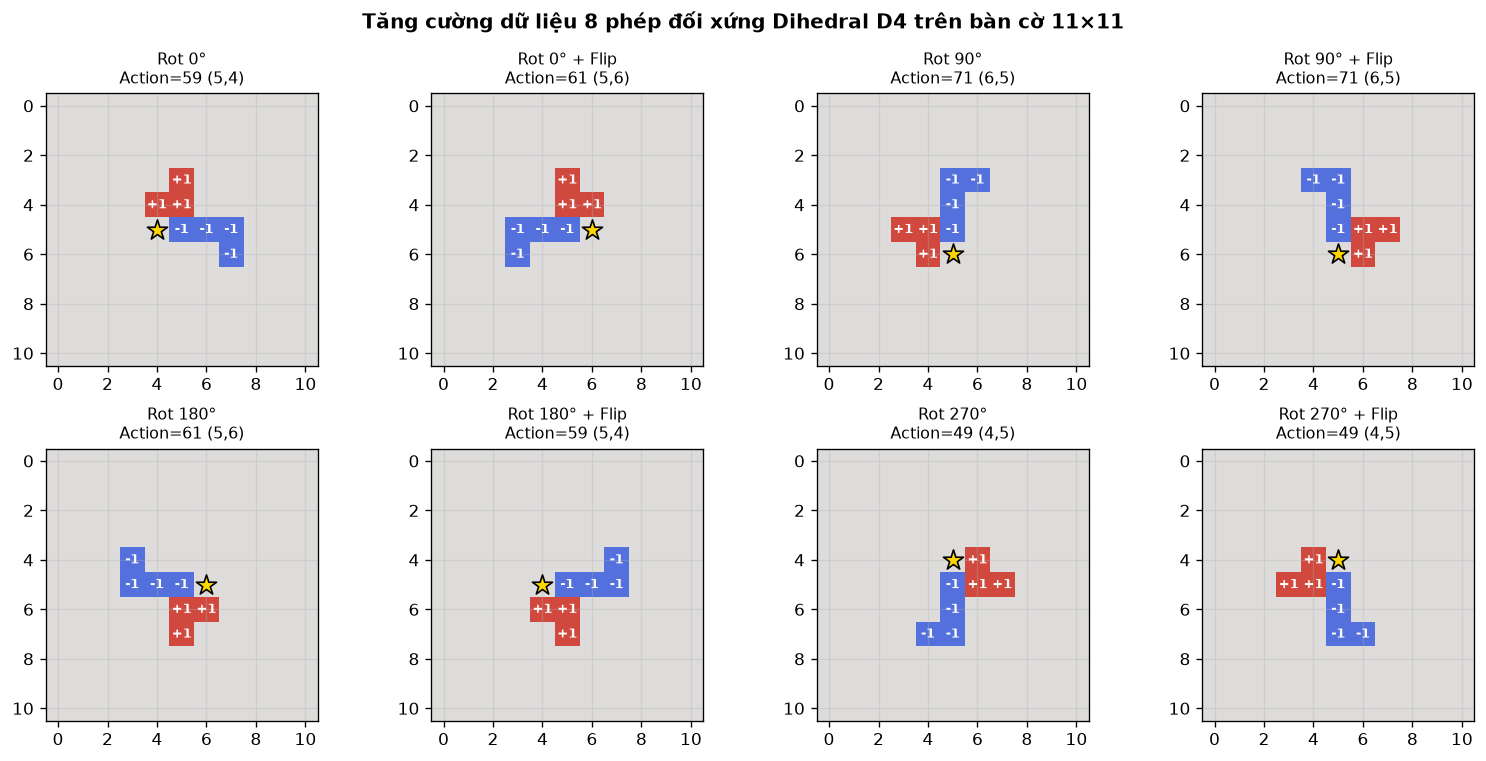

,Transform ID,Transform,Expert Action,Row,Col
0,1,Rot 0°,59,5,4
1,2,Rot 0° + Flip,61,5,6
2,3,Rot 90°,71,6,5
3,4,Rot 90° + Flip,71,6,5
4,5,Rot 180°,61,5,6
5,6,Rot 180° + Flip,59,5,4
6,7,Rot 270°,49,4,5
7,8,Rot 270° + Flip,49,4,5


In [3]:
sym_env = CaroEnv(BOARD_SIZE, WIN_LENGTH)
for m in [60, 48, 61, 49, 73, 38, 62]:
    sym_env.step(m)

canonical_state = encode_board(sym_env.board, sym_env.current_player)
expert_move = expert_select_action(sym_env)
aug_pairs = augment_state_action(canonical_state, expert_move, board_size=BOARD_SIZE)

transform_names = [
    "Rot 0°", "Rot 0° + Flip",
    "Rot 90°", "Rot 90° + Flip",
    "Rot 180°", "Rot 180° + Flip",
    "Rot 270°", "Rot 270° + Flip",
]

sym_rows = []
fig, axes = plt.subplots(2, 4, figsize=(13, 6.4))
for idx, ((aug_s, aug_a), t_name) in enumerate(zip(aug_pairs, transform_names)):
    ax = axes[idx // 4, idx % 4]
    grid = aug_s.reshape(BOARD_SIZE, BOARD_SIZE)
    r_act, c_act = divmod(aug_a, BOARD_SIZE)
    sym_rows.append({
        "Transform ID": idx + 1,
        "Transform": t_name,
        "Expert Action": aug_a,
        "Row": r_act,
        "Col": c_act,
    })
    ax.imshow(grid, cmap="coolwarm", vmin=-1.2, vmax=1.2)
    for r in range(BOARD_SIZE):
        for c in range(BOARD_SIZE):
            v = int(grid[r, c])
            if v != 0:
                ax.text(c, r, f"{v:+d}", ha="center", va="center", color="white", fontsize=8, fontweight="bold")
    ax.scatter([c_act], [r_act], marker="*", s=160, color="gold", edgecolors="black", zorder=5)
    ax.set_title(f"{t_name}\nAction={aug_a} ({r_act},{c_act})", fontsize=9.5)
    ax.set_xticks(range(0, BOARD_SIZE, 2))
    ax.set_yticks(range(0, BOARD_SIZE, 2))

fig.suptitle("Tăng cường dữ liệu 8 phép đối xứng Dihedral D4 trên bàn cờ 11×11", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_fig_symmetry_augmentation.png", bbox_inches="tight")
plt.show()

sym_df = pd.DataFrame(sym_rows)
sym_df.to_csv(TABLE_DIR / "04_table_symmetry_samples.csv", index=False, encoding="utf-8-sig")
display(sym_df)

## 4. Sinh Dữ Liệu Tự Chơi (`Expert vs Non-Expert`), Lưu 2 Phiên Bản ở 2 Nơi (`data/*.npz` & `results/tables/*.csv`) và Huấn Luyện

### Quy ước 2 phiên bản dữ liệu lưu đồng thời tại 2 thư mục (`data/` và `results/tables/`):
1. **Phiên bản 1 — Bộ dữ liệu chính thức (Có đối xứng $D_4$ cho Train + Validation ván đấu độc lập)**:
   - Bản nén nhị phân Tensor (`.npz`): [`data/04_cnn_expert_train_val_11x11.npz`](file:///f:/TTNTNC/Caro/caro_ai_11x11/data/04_cnn_expert_train_val_11x11.npz) (`11,384` mẫu `X_train` + `245` mẫu `X_val`).
   - Bản bảng phẳng (`.csv`): [`results/tables/04_cnn_dataset_train_val_11x11.csv`](file:///f:/TTNTNC/Caro/caro_ai_11x11/results/tables/04_cnn_dataset_train_val_11x11.csv) (`11,629` dòng với các cột `sample_id, split, action, row, col, my_stones, opp_stones, board_flat`).
2. **Phiên bản 2 — Bộ dữ liệu đối chứng Ablation (Không dùng đối xứng $D_4$, `augment_symmetry=False`)**:
   - Bản nén nhị phân Tensor (`.npz`): [`data/04_cnn_expert_train_noaug_11x11.npz`](file:///f:/TTNTNC/Caro/caro_ai_11x11/data/04_cnn_expert_train_noaug_11x11.npz) (`1,423` mẫu `X`).
   - Bản bảng phẳng (`.csv`): [`results/tables/04_cnn_dataset_train_noaug_11x11.csv`](file:///f:/TTNTNC/Caro/caro_ai_11x11/results/tables/04_cnn_dataset_train_noaug_11x11.csv) (`1,423` dòng).
3. **Bảng mô tả siêu dữ liệu (Metadata)**:
   - Lưu đồng thời tại [`data/04_cnn_dataset_metadata.csv`](file:///f:/TTNTNC/Caro/caro_ai_11x11/data/04_cnn_dataset_metadata.csv) và [`results/tables/04_cnn_dataset_metadata.csv`](file:///f:/TTNTNC/Caro/caro_ai_11x11/results/tables/04_cnn_dataset_metadata.csv).

Đang nạp sẵn 3 checkpoint đã huấn luyện từ checkpoints/ (đặt RETRAIN_MODELS=True nếu muốn huấn luyện lại).


Version,NPZ File (data/),CSV File (results/tables/),Split,Games,Symmetry D4,Samples (N),NPZ Key & Shape,NPZ Size (KB),CSV Size (KB)
Version 1 (With D4 Symmetry - Train),data/04_cnn_expert_train_val_11x11.npz,results/tables/04_cnn_dataset_train_val_11x11.csv,train_aug,170,Yes (x8),11384,"X_train: (11384, 11, 11, 1), y_train: (11384,)",113.13,3128.60
Version 1 (Unseen Games - Validation),data/04_cnn_expert_train_val_11x11.npz,results/tables/04_cnn_dataset_train_val_11x11.csv,val_unseen,30,No (x1),245,"X_val: (245, 11, 11, 1), y_val: (245,)",113.13,3128.60
Version 2 (No D4 Symmetry - Train Ablation),data/04_cnn_expert_train_noaug_11x11.npz,results/tables/04_cnn_dataset_train_noaug_11x11.csv,train_noaug,170,No (x1),1423,"X: (1423, 11, 11, 1), y: (1423,)",13.43,384.63


Epoch,Fast Train Loss,Fast Val Loss (Unseen),Fast Train Acc (%),Fast Val Acc (%),Strong Train Loss,Strong Val Loss (Unseen),Strong Train Acc (%),Strong Val Acc (%),NoAug Val Acc (%)
1,3.8374,3.3259,12.57,25.71,3.8759,3.3329,11.77,22.86,4.49
2,3.0801,2.8931,26.65,32.24,3.0484,2.9488,24.38,30.20,9.39
3,2.5726,2.7028,33.35,31.84,2.6496,2.8033,31.03,32.24,16.33
4,2.3033,2.6629,38.64,39.59,2.4299,2.7363,36.01,33.88,23.27
5,2.1080,2.5390,43.34,37.96,2.2363,2.6111,40.28,33.47,21.63
6,1.9677,2.5895,46.26,42.45,2.0934,2.6748,43.74,32.65,27.76
7,1.8681,2.4585,48.49,38.78,1.9681,2.6061,46.46,37.96,23.27
8,1.7684,2.4942,51.13,42.04,1.8622,2.4673,48.97,41.63,28.16
9,1.6840,2.4767,52.90,40.82,1.7490,2.5538,51.06,40.41,26.53
10,1.6044,2.4551,54.57,44.08,1.6726,2.4712,53.10,40.41,27.76


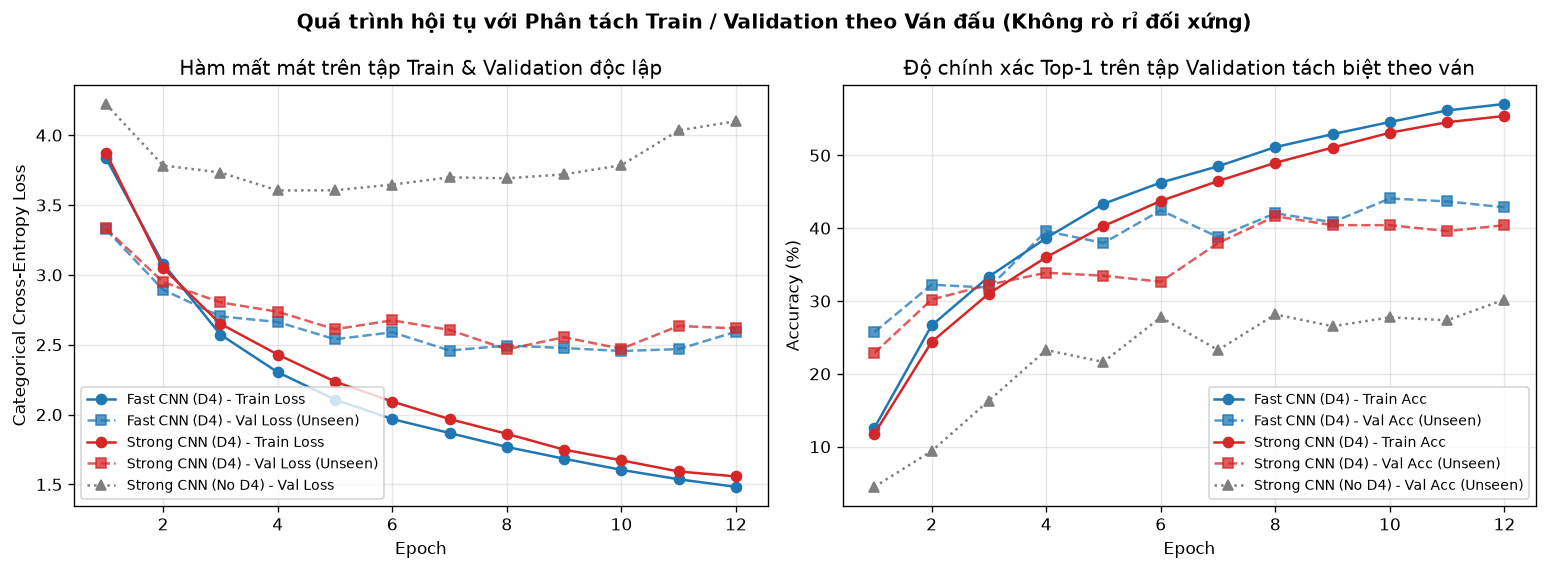

In [4]:
NUM_TRAIN_GAMES = 170
NUM_VAL_GAMES = 30
EPOCHS = 12
BATCH_SIZE = 128
LEARNING_RATE = 0.0012
WEIGHT_DECAY = 1.5e-3
RETRAIN_MODELS = False  # Đặt True nếu muốn ép huấn luyện lại cả 3 mạng từ đầu dù đã có checkpoint

# Đường dẫn lưu Phiên bản 1 & Phiên bản 2 ở cả 2 nơi: data/ (.npz) và results/tables/ (.csv)
train_val_npz_path = DATA_DIR / "04_cnn_expert_train_val_11x11.npz"
train_noaug_npz_path = DATA_DIR / "04_cnn_expert_train_noaug_11x11.npz"
train_val_csv_path = TABLE_DIR / "04_cnn_dataset_train_val_11x11.csv"
train_noaug_csv_path = TABLE_DIR / "04_cnn_dataset_train_noaug_11x11.csv"

t0_gen = time.perf_counter()
# 1. Phiên bản 1: Sinh (hoặc nạp) bộ dữ liệu chuẩn (Train có D4 + Val độc lập) -> lưu .npz tại data/ và .csv tại results/tables/
X_train_aug, y_train_aug, X_val_unseen, y_val_unseen = generate_expert_train_val_datasets(
    num_train_games=NUM_TRAIN_GAMES,
    num_val_games=NUM_VAL_GAMES,
    board_size=BOARD_SIZE,
    win_length=WIN_LENGTH,
    random_prob=0.5,
    augment_train_symmetry=True,
    augment_val_symmetry=False,
    seed=SEED,
    save_path=train_val_npz_path,
    load_if_exists=not RETRAIN_MODELS,
)
export_dataset_to_csv(X_train_aug, y_train_aug, train_val_csv_path, split_label="train_aug", append=False)
export_dataset_to_csv(X_val_unseen, y_val_unseen, train_val_csv_path, split_label="val_unseen", append=True)

# 2. Phiên bản 2: Sinh (hoặc nạp) bộ dữ liệu đối chứng không đối xứng D4 -> lưu .npz tại data/ và .csv tại results/tables/
if train_noaug_npz_path.exists() and not RETRAIN_MODELS:
    with np.load(train_noaug_npz_path, allow_pickle=False) as d_noaug:
        X_train_noaug = np.asarray(d_noaug["X"], dtype=np.float32)
        y_train_noaug = np.asarray(d_noaug["y"], dtype=np.int64)
else:
    X_train_noaug, y_train_noaug = generate_expert_dataset(
        num_games=NUM_TRAIN_GAMES,
        board_size=BOARD_SIZE,
        win_length=WIN_LENGTH,
        random_prob=0.5,
        augment_symmetry=False,
        seed=SEED,
        save_path=train_noaug_npz_path,
    )
export_dataset_to_csv(X_train_noaug, y_train_noaug, train_noaug_csv_path, split_label="train_noaug", append=False)

# 3. Tự động tạo và lưu bảng mô tả metadata ở cả data/ và results/tables/
dataset_meta_df = pd.DataFrame([
    {
        "Version": "Version 1 (With D4 Symmetry - Train)",
        "NPZ File (data/)": f"data/{train_val_npz_path.name}",
        "CSV File (results/tables/)": f"results/tables/{train_val_csv_path.name}",
        "Split": "train_aug",
        "Games": NUM_TRAIN_GAMES,
        "Symmetry D4": "Yes (x8)",
        "Samples (N)": int(X_train_aug.shape[0]),
        "NPZ Key & Shape": f"X_train: {tuple(X_train_aug.shape)}, y_train: {tuple(y_train_aug.shape)}",
        "NPZ Size (KB)": round(train_val_npz_path.stat().st_size / 1024.0, 2),
        "CSV Size (KB)": round(train_val_csv_path.stat().st_size / 1024.0, 2),
    },
    {
        "Version": "Version 1 (Unseen Games - Validation)",
        "NPZ File (data/)": f"data/{train_val_npz_path.name}",
        "CSV File (results/tables/)": f"results/tables/{train_val_csv_path.name}",
        "Split": "val_unseen",
        "Games": NUM_VAL_GAMES,
        "Symmetry D4": "No (x1)",
        "Samples (N)": int(X_val_unseen.shape[0]),
        "NPZ Key & Shape": f"X_val: {tuple(X_val_unseen.shape)}, y_val: {tuple(y_val_unseen.shape)}",
        "NPZ Size (KB)": round(train_val_npz_path.stat().st_size / 1024.0, 2),
        "CSV Size (KB)": round(train_val_csv_path.stat().st_size / 1024.0, 2),
    },
    {
        "Version": "Version 2 (No D4 Symmetry - Train Ablation)",
        "NPZ File (data/)": f"data/{train_noaug_npz_path.name}",
        "CSV File (results/tables/)": f"results/tables/{train_noaug_csv_path.name}",
        "Split": "train_noaug",
        "Games": NUM_TRAIN_GAMES,
        "Symmetry D4": "No (x1)",
        "Samples (N)": int(X_train_noaug.shape[0]),
        "NPZ Key & Shape": f"X: {tuple(X_train_noaug.shape)}, y: {tuple(y_train_noaug.shape)}",
        "NPZ Size (KB)": round(train_noaug_npz_path.stat().st_size / 1024.0, 2),
        "CSV Size (KB)": round(train_noaug_csv_path.stat().st_size / 1024.0, 2),
    },
])
dataset_meta_df.to_csv(DATA_DIR / "04_cnn_dataset_metadata.csv", index=False, encoding="utf-8-sig")
dataset_meta_df.to_csv(TABLE_DIR / "04_cnn_dataset_metadata.csv", index=False, encoding="utf-8-sig")
display(dataset_meta_df)

# 4. Huấn luyện (nếu chưa có sẵn checkpoint/lịch sử hoặc RETRAIN_MODELS=True) và nạp 3 mô hình
fast_ckpt_path = CHECKPOINTS_DIR / "cnn_fast_11x11.npz"
strong_ckpt_path = CHECKPOINTS_DIR / "cnn_strong_11x11.npz"
noaug_ckpt_path = CHECKPOINTS_DIR / "cnn_strong_noaug_11x11.npz"
history_csv_path = TABLE_DIR / "04_table_training_history.csv"

need_training = RETRAIN_MODELS or not (
    fast_ckpt_path.exists()
    and strong_ckpt_path.exists()
    and noaug_ckpt_path.exists()
    and history_csv_path.exists()
)

if need_training:
    print("\n[1/3] Huấn luyện Fast Policy Network (2 lớp Dense, có D4 Symmetry)...")
    fast_cnn = CNNAgent(
        name="CNN Fast Policy", model_type="fast", model_path=None,
        kernel_size=5, conv_filters=64, learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY, seed=SEED,
    )
    hist_fast = fast_cnn.train_from_dataset(
        X=X_train_aug, y=y_train_aug, epochs=EPOCHS, batch_size=BATCH_SIZE,
        validation_data=(X_val_unseen, y_val_unseen), learning_rate=LEARNING_RATE, verbose=1,
    )
    fast_cnn.save_model(fast_ckpt_path)

    print("\n[2/3] Huấn luyện Strong Policy Network (3 lớp Dense, có D4 Symmetry)...")
    strong_cnn = CNNAgent(
        name="CNN Strong Policy", model_type="strong", model_path=None,
        kernel_size=5, conv_filters=64, learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY, seed=SEED,
    )
    hist_strong = strong_cnn.train_from_dataset(
        X=X_train_aug, y=y_train_aug, epochs=EPOCHS, batch_size=BATCH_SIZE,
        validation_data=(X_val_unseen, y_val_unseen), learning_rate=LEARNING_RATE, verbose=1,
    )
    strong_cnn.save_model(strong_ckpt_path)

    print("\n[3/3] Huấn luyện Strong Policy Network (Không dùng D4 Symmetry)...")
    strong_noaug_cnn = CNNAgent(
        name="CNN Strong (No SymAug)", model_type="strong", model_path=None,
        kernel_size=5, conv_filters=64, learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY, seed=SEED,
    )
    hist_noaug = strong_noaug_cnn.train_from_dataset(
        X=X_train_noaug, y=y_train_noaug, epochs=EPOCHS, batch_size=64,
        validation_data=(X_val_unseen, y_val_unseen), learning_rate=LEARNING_RATE, verbose=1,
    )
    strong_noaug_cnn.save_model(noaug_ckpt_path)

    train_df = pd.DataFrame({
        "Epoch": list(range(1, EPOCHS + 1)),
        "Fast Train Loss": np.round(hist_fast["loss"], 4),
        "Fast Val Loss (Unseen)": np.round(hist_fast["val_loss"], 4),
        "Fast Train Acc (%)": np.round(np.array(hist_fast["accuracy"]) * 100, 2),
        "Fast Val Acc (%)": np.round(np.array(hist_fast["val_accuracy"]) * 100, 2),
        "Strong Train Loss": np.round(hist_strong["loss"], 4),
        "Strong Val Loss (Unseen)": np.round(hist_strong["val_loss"], 4),
        "Strong Train Acc (%)": np.round(np.array(hist_strong["accuracy"]) * 100, 2),
        "Strong Val Acc (%)": np.round(np.array(hist_strong["val_accuracy"]) * 100, 2),
        "NoAug Val Acc (%)": np.round(np.array(hist_noaug["val_accuracy"]) * 100, 2),
    })
    train_df.to_csv(history_csv_path, index=False, encoding="utf-8-sig")
else:
    print("Đang nạp sẵn 3 checkpoint đã huấn luyện từ checkpoints/ (đặt RETRAIN_MODELS=True nếu muốn huấn luyện lại).")
    fast_cnn = CNNAgent(name="CNN Fast Policy", model_type="fast", model_path=fast_ckpt_path, seed=SEED)
    strong_cnn = CNNAgent(name="CNN Strong Policy", model_type="strong", model_path=strong_ckpt_path, seed=SEED)
    strong_noaug_cnn = CNNAgent(name="CNN Strong (No SymAug)", model_type="strong", model_path=noaug_ckpt_path, seed=SEED)
    train_df = pd.read_csv(history_csv_path)

display(train_df)

# 5. Vẽ và lưu biểu đồ đường cong hội tụ Loss & Accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ep_axis = train_df["Epoch"]
ax1.plot(ep_axis, train_df["Fast Train Loss"], "o-", label="Fast CNN (D4) - Train Loss", color="#1f77b4")
ax1.plot(ep_axis, train_df["Fast Val Loss (Unseen)"], "s--", label="Fast CNN (D4) - Val Loss (Unseen)", color="#1f77b4", alpha=0.75)
ax1.plot(ep_axis, train_df["Strong Train Loss"], "o-", label="Strong CNN (D4) - Train Loss", color="#d62728")
ax1.plot(ep_axis, train_df["Strong Val Loss (Unseen)"], "s--", label="Strong CNN (D4) - Val Loss (Unseen)", color="#d62728", alpha=0.75)
ax1.set_title("Hàm mất mát trên tập Train & Validation độc lập")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Categorical Cross-Entropy Loss")
ax1.legend(fontsize=8.5)

ax2.plot(ep_axis, train_df["Fast Train Acc (%)"], "o-", label="Fast CNN (D4) - Train Acc", color="#1f77b4")
ax2.plot(ep_axis, train_df["Fast Val Acc (%)"], "s--", label="Fast CNN (D4) - Val Acc (Unseen)", color="#1f77b4", alpha=0.75)
ax2.plot(ep_axis, train_df["Strong Train Acc (%)"], "o-", label="Strong CNN (D4) - Train Acc", color="#d62728")
ax2.plot(ep_axis, train_df["Strong Val Acc (%)"], "s--", label="Strong CNN (D4) - Val Acc (Unseen)", color="#d62728", alpha=0.75)
ax2.plot(ep_axis, train_df["NoAug Val Acc (%)"], "^:", label="Strong CNN (No D4) - Val Acc (Unseen)", color="#7f7f7f")
ax2.set_title("Độ chính xác Top-1 trên tập Validation tách biệt theo ván")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend(fontsize=8.5)

fig.suptitle("Quá trình hội tụ với Phân tách Train / Validation theo Ván đấu (Không rò rỉ đối xứng)", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_fig_training_curves.png", bbox_inches="tight")
plt.show()

## 5. Kiểm chứng Tình huống Chiến thuật: So sánh minh bạch `Pure CNN` vs `Hybrid CNN`

Đánh giá trung thực năng lực nội tại của mạng CNN khi **tắt hoàn toàn luật chiến thuật (`use_tactical_shortcut=False`)** so với khi **bật luật chiến thuật (`use_tactical_shortcut=True`)** trên 4 tình huống chiến thuật cốt lõi.

In [5]:
def make_test_env(x_stones=(), o_stones=(), current_player=1) -> CaroEnv:
    test_env = CaroEnv(BOARD_SIZE, WIN_LENGTH)
    for r, c in x_stones:
        test_env.board[r, c] = 1
        test_env.history.append(r * BOARD_SIZE + c)
    for r, c in o_stones:
        test_env.board[r, c] = -1
        test_env.history.append(r * BOARD_SIZE + c)
    test_env.current_player = current_player
    return test_env


tactical_scenarios = [
    (
        "1. Thắng ngay chuỗi 5 (Win in 1)",
        make_test_env(x_stones=[(5, 3), (5, 4), (5, 5), (5, 6)], o_stones=[(3, 3), (3, 4), (3, 5), (3, 6)], current_player=1),
        {(5, 2), (5, 7)},
    ),
    (
        "2. Chặn đối thủ thắng ngay (Block Win in 1)",
        make_test_env(x_stones=[(5, 1), (5, 2), (5, 3), (5, 4)], o_stones=[(4, 2), (4, 3), (4, 4)], current_player=-1),
        {(5, 0), (5, 5)},
    ),
    (
        "3. Tạo chuỗi 4 mở 2 đầu (Create Open-4)",
        make_test_env(x_stones=[(3, 3), (4, 4), (5, 5)], o_stones=[(3, 4), (4, 5), (5, 6)], current_player=1),
        {(2, 2), (6, 6)},
    ),
    (
        "4. Chặn chuỗi 4 mở 2 đầu của đối thủ (Block Open-4)",
        make_test_env(x_stones=[(3, 5), (4, 5), (5, 5)], o_stones=[(4, 4), (5, 4)], current_player=-1),
        {(2, 5), (6, 5)},
    ),
]

pure_eval_agent = CNNAgent(
    name="Strong_Pure_NoTactical",
    model_type="strong",
    model_path=strong_ckpt_path,
    use_tactical_shortcut=False,
    use_mix_mcts=False,
    seed=SEED,
)
hybrid_eval_agent = CNNAgent(
    name="Strong_Hybrid_WithTactical",
    model_type="strong",
    model_path=strong_ckpt_path,
    use_tactical_shortcut=True,
    use_mix_mcts=False,
    seed=SEED,
)

tactical_records = []
for title, t_env, expected_coords in tactical_scenarios:
    pure_probs = pure_eval_agent.predict_probs(t_env, restrict_to_candidates=True)
    pure_act = pure_eval_agent.select_action(t_env)
    pure_coord = divmod(pure_act, BOARD_SIZE)
    pure_pass = pure_coord in expected_coords
    expected_prob_sum = sum(float(pure_probs[r * BOARD_SIZE + c]) for (r, c) in expected_coords)

    hybrid_act = hybrid_eval_agent.select_action(t_env)
    hybrid_coord = divmod(hybrid_act, BOARD_SIZE)
    hybrid_pass = hybrid_coord in expected_coords

    tactical_records.append({
        "Tình huống": title,
        "Tọa độ đúng": str(sorted(list(expected_coords))),
        "Pure CNN chọn": f"{pure_coord}",
        "Xác suất CNN tại ô đúng": round(expected_prob_sum, 4),
        "Pure CNN Pass": "PASS" if pure_pass else "FAIL",
        "Hybrid CNN chọn": f"{hybrid_coord}",
        "Hybrid Stage": hybrid_eval_agent.last_decision_stage,
        "Hybrid Pass": "PASS" if hybrid_pass else "FAIL",
    })
    assert hybrid_pass, f"Hybrid CNN failed on {title}"

tactical_df = pd.DataFrame(tactical_records)
tactical_df.to_csv(TABLE_DIR / "04_table_tactical_checks.csv", index=False, encoding="utf-8-sig")
display(tactical_df)

,Tình huống,Tọa độ đúng,Pure CNN chọn,Xác suất CNN tại ô đúng,Pure CNN Pass,Hybrid CNN chọn,Hybrid Stage,Hybrid Pass
0,1. Thắng ngay chuỗi 5 (Win in 1),"[(5, 2), (5, 7)]","(5, 2)",0.9311,PASS,"(5, 2)",tactical_win_5,PASS
1,2. Chặn đối thủ thắng ngay (Block Win in 1),"[(5, 0), (5, 5)]","(5, 6)",0.1132,FAIL,"(5, 5)",tactical_block_win_5,PASS
2,3. Tạo chuỗi 4 mở 2 đầu (Create Open-4),"[(2, 2), (6, 6)]","(6, 6)",0.9075,PASS,"(2, 2)",tactical_create_open_4,PASS
3,4. Chặn chuỗi 4 mở 2 đầu của đối thủ (Block Op...,"[(2, 5), (6, 5)]","(6, 5)",0.7698,PASS,"(6, 5)",tactical_block_open_4,PASS


## 6. Ablation Study 1 — Đánh giá Kiến trúc (`Fast` vs `Strong`), Đối xứng $D_4$, `Deterministic`/`Stochastic` và `Tactical Shortcut` (`100 ván / cấu hình`)

Mỗi cấu hình dưới đây thi đấu **100 ván cân bằng lượt đi (50 ván cầm X đi trước, 50 ván cầm O đi sau)** trước `Non-Expert (50%)` bằng hàm `run_matchup()` để định lượng đóng góp thực sự của từng thành phần.

1. Strong Pure (No SymAug)   | W/D/L = 18/ 0/82 | Score =  18.0% ±  7.6% | Time = 0.49 ms
2. Fast Pure (With SymAug)   | W/D/L = 52/ 0/48 | Score =  52.0% ±  9.8% | Time = 0.49 ms
3. Strong Pure (With SymAug) | W/D/L = 46/ 0/54 | Score =  46.0% ±  9.8% | Time = 0.51 ms
4. Fast Hybrid (Det)         | W/D/L = 97/ 2/ 1 | Score =  98.0% ±  2.4% | Time = 0.68 ms
5. Strong Hybrid (Stoch)     | W/D/L = 92/ 1/ 7 | Score =  92.5% ±  5.1% | Time = 0.72 ms
6. Strong Hybrid (Det)       | W/D/L = 98/ 0/ 2 | Score =  98.0% ±  2.8% | Time = 0.68 ms


,Configuration,Games,A Wins,B Wins,Draws,Win Rate (%),Draw Rate (%),Loss Rate (%),Score Rate (%),CI95 (±%),Avg Moves,Avg Time A (ms)
0,1. Strong Pure (No SymAug),100,18,82,0,18.0,0.0,82.0,18.0,7.57,20.82,0.493
1,2. Fast Pure (With SymAug),100,52,48,0,52.0,0.0,48.0,52.0,9.84,19.20,0.495
2,3. Strong Pure (With SymAug),100,46,54,0,46.0,0.0,54.0,46.0,9.82,18.84,0.513
3,4. Fast Hybrid (Det),100,97,1,2,97.0,2.0,1.0,98.0,2.38,19.72,0.678
4,5. Strong Hybrid (Stoch),100,92,7,1,92.0,1.0,7.0,92.5,5.09,23.78,0.721
5,6. Strong Hybrid (Det),100,98,2,0,98.0,0.0,2.0,98.0,2.76,19.34,0.681


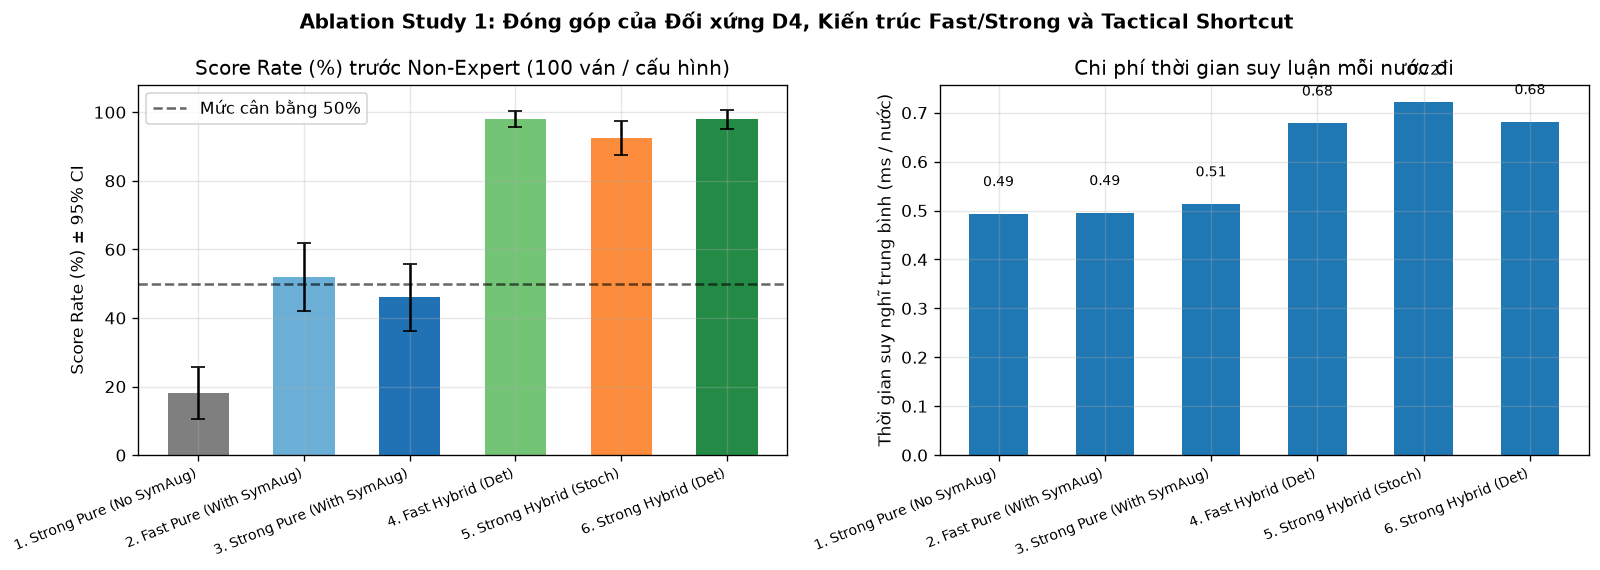

In [6]:
ablation_configs = [
    (
        "1. Strong Pure (No SymAug)",
        lambda s: CNNAgent(name="Strong Pure (No SymAug)", model_type="strong", model_path=noaug_ckpt_path, deterministic=True, use_tactical_shortcut=False, use_mix_mcts=False, seed=s),
    ),
    (
        "2. Fast Pure (With SymAug)",
        lambda s: CNNAgent(name="Fast Pure (With SymAug)", model_type="fast", model_path=fast_ckpt_path, deterministic=True, use_tactical_shortcut=False, use_mix_mcts=False, seed=s),
    ),
    (
        "3. Strong Pure (With SymAug)",
        lambda s: CNNAgent(name="Strong Pure (With SymAug)", model_type="strong", model_path=strong_ckpt_path, deterministic=True, use_tactical_shortcut=False, use_mix_mcts=False, seed=s),
    ),
    (
        "4. Fast Hybrid (Det)",
        lambda s: CNNAgent(name="Fast Hybrid (Det)", model_type="fast", model_path=fast_ckpt_path, deterministic=True, use_tactical_shortcut=True, use_mix_mcts=False, seed=s),
    ),
    (
        "5. Strong Hybrid (Stoch)",
        lambda s: CNNAgent(name="Strong Hybrid (Stoch)", model_type="strong", model_path=strong_ckpt_path, deterministic=False, temperature=0.75, use_tactical_shortcut=True, use_mix_mcts=False, seed=s),
    ),
    (
        "6. Strong Hybrid (Det)",
        lambda s: CNNAgent(name="Strong Hybrid (Det)", model_type="strong", model_path=strong_ckpt_path, deterministic=True, use_tactical_shortcut=True, use_mix_mcts=False, seed=s),
    ),
]

ablation1_rows = []
for cfg_name, factory_fn in ablation_configs:
    rows_cfg = run_matchup(
        factory_a=factory_fn,
        factory_b=lambda s: NonExpertBaselineAgent(random_prob=0.5, seed=s, name="Non-Expert (50%)"),
        games=GAMES_PER_MATCHUP,
        board_size=BOARD_SIZE,
        win_length=WIN_LENGTH,
        seed=SEED,
    )
    summary_cfg = summarize_matchup_rows(cfg_name, rows_cfg)
    ablation1_rows.append(summary_cfg)
    print(
        f"{cfg_name:28s} | W/D/L = {summary_cfg['A Wins']:2d}/{summary_cfg['Draws']:2d}/{summary_cfg['B Wins']:2d} | "
        f"Score = {summary_cfg['Score Rate (%)']:5.1f}% ± {summary_cfg['CI95 (±%)']:4.1f}% | "
        f"Time = {summary_cfg['Avg Time A (ms)']:.2f} ms"
    )

ablation1_df = pd.DataFrame(ablation1_rows)
ablation1_df.to_csv(TABLE_DIR / "04_table_ablation_architecture.csv", index=False, encoding="utf-8-sig")
display(ablation1_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))
x_idx = np.arange(len(ablation1_df))
labels_ab1 = ablation1_df["Configuration"]

ax1.bar(x_idx, ablation1_df["Score Rate (%)"], yerr=ablation1_df["CI95 (±%)"], capsize=4, color=["#7f7f7f", "#6baed6", "#2171b5", "#74c476", "#fd8d3c", "#238b45"], width=0.58)
ax1.axhline(50.0, color="black", linestyle="--", alpha=0.6, label="Mức cân bằng 50%")
ax1.set_xticks(x_idx)
ax1.set_xticklabels(labels_ab1, rotation=22, ha="right", fontsize=8.5)
ax1.set_ylabel("Score Rate (%) ± 95% CI")
ax1.set_ylim(0, 108)
ax1.set_title("Score Rate (%) trước Non-Expert (100 ván / cấu hình)")
ax1.legend()

bars_t = ax2.bar(x_idx, ablation1_df["Avg Time A (ms)"], color="#1f77b4", width=0.55)
ax2.set_xticks(x_idx)
ax2.set_xticklabels(labels_ab1, rotation=22, ha="right", fontsize=8.5)
ax2.set_ylabel("Thời gian suy nghĩ trung bình (ms / nước)")
ax2.set_title("Chi phí thời gian suy luận mỗi nước đi")
for b in bars_t:
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width() / 2, h + 0.05, f"{h:.2f}", ha="center", va="bottom", fontsize=8.5)

fig.suptitle("Ablation Study 1: Đóng góp của Đối xứng D4, Kiến trúc Fast/Strong và Tactical Shortcut", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_fig_ablation_architecture.png", bbox_inches="tight")
plt.show()

## 7. Thực nghiệm Đấu đối kháng chính thức (100 ván / cặp, cân bằng 50 X / 50 O trực tiếp trong Notebook)

Chạy **5 cặp đấu chính thức** (mỗi cặp **100 ván**, chia đều 50 ván A cầm X đi trước và 50 ván A cầm O đi sau) bằng hàm `run_matchup()` và `play_game()`.

Hoàn thành 1. Strong Pure CNN (No Tactical) vs Random      : 100 ván (3.1s)
Hoàn thành 2. Fast Hybrid CNN vs Non-Expert (50%)          : 100 ván (3.6s)
Hoàn thành 3. Strong Hybrid CNN vs Non-Expert (50%)        : 100 ván (3.6s)
Hoàn thành 4. Strong Hybrid CNN vs Fast Hybrid CNN         : 100 ván (9.3s)
Hoàn thành 5. Strong CNN + Mixed MCTS vs Strong Hybrid CNN : 100 ván (73.9s)
Đã lưu log riêng cặp đấu: results/tables/04_cnn_matchup_1_strong_pure_vs_random_logs.csv (100 ván)
Đã lưu log riêng cặp đấu: results/tables/04_cnn_matchup_2_fast_hybrid_vs_nonexpert_logs.csv (100 ván)
Đã lưu log riêng cặp đấu: results/tables/04_cnn_matchup_3_strong_hybrid_vs_nonexpert_logs.csv (100 ván)
Đã lưu log riêng cặp đấu: results/tables/04_cnn_matchup_4_strong_hybrid_vs_fast_hybrid_logs.csv (100 ván)
Đã lưu log riêng cặp đấu: results/tables/04_cnn_matchup_5_strong_mix_mcts_vs_strong_hybrid_logs.csv (100 ván)

Bảng tổng hợp Thắng / Hòa / Thua và Score (100 ván / cặp):


,Matchup,Games,A wins,B wins,Draws,A win rate (%),B win rate (%),Draw rate (%),A Score rate (%),CI95 (±%),Avg moves,Avg A decision (ms),Avg B decision (ms)
0,1. Strong Pure CNN (No Tactical) vs Random,100,95,5,0,95.0,5.0,0.0,95.0,4.29,17.17,0.516,0.012
1,2. Fast Hybrid CNN vs Non-Expert (50%),100,97,2,1,97.0,2.0,1.0,97.5,2.91,19.81,0.689,0.253
2,3. Strong Hybrid CNN vs Non-Expert (50%),100,99,1,0,99.0,1.0,0.0,99.0,1.96,20.59,0.670,0.242
3,4. Strong Hybrid CNN vs Fast Hybrid CNN,100,40,52,8,40.0,52.0,8.0,44.0,9.37,52.84,0.765,0.780
4,5. Strong CNN + Mixed MCTS vs Strong Hybrid CNN,100,64,32,4,64.0,32.0,4.0,66.0,9.12,45.21,31.473,0.964



Bảng phân tích hiệu năng tính toán:


,matchup,games,avg_moves,avg_A_ms,avg_B_ms,avg_A_search_count,avg_B_search_count
0,1. Strong Pure CNN (No Tactical) vs Random,100,17.17,0.516,0.012,1.000,1.000
1,2. Fast Hybrid CNN vs Non-Expert (50%),100,19.81,0.689,0.253,22.135,52.653
2,3. Strong Hybrid CNN vs Non-Expert (50%),100,20.59,0.670,0.242,23.560,53.143
3,4. Strong Hybrid CNN vs Fast Hybrid CNN,100,52.84,0.765,0.780,21.256,19.874
4,5. Strong CNN + Mixed MCTS vs Strong Hybrid CNN,100,45.21,31.473,0.964,37.817,23.709


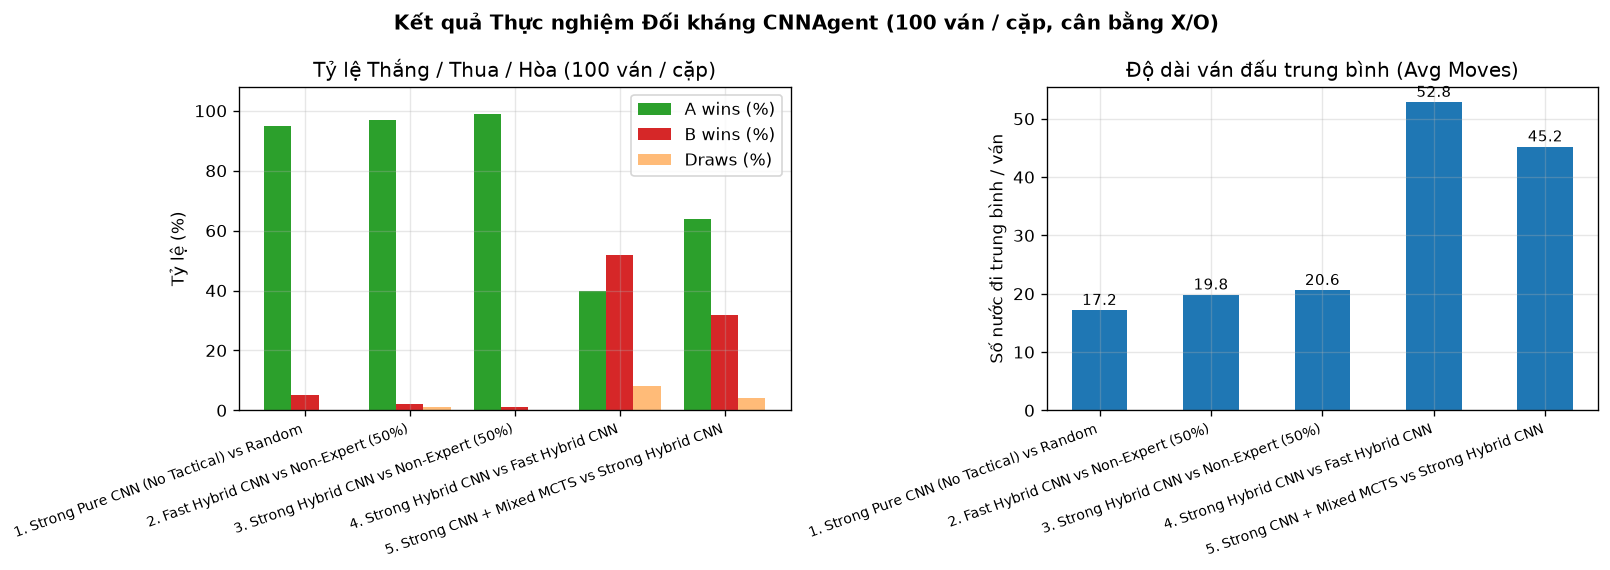

In [7]:
matchups = {
    "1. Strong Pure CNN (No Tactical) vs Random": (
        lambda seed: CNNAgent(
            name="Strong Pure CNN",
            model_type="strong",
            model_path=strong_ckpt_path,
            use_tactical_shortcut=False,
            use_mix_mcts=False,
            seed=seed,
        ),
        lambda seed: RandomBaselineAgent(seed=seed + 1, name="Random"),
    ),
    "2. Fast Hybrid CNN vs Non-Expert (50%)": (
        lambda seed: CNNAgent(
            name="Fast Hybrid CNN",
            model_type="fast",
            model_path=fast_ckpt_path,
            use_tactical_shortcut=True,
            use_mix_mcts=False,
            seed=seed,
        ),
        lambda seed: NonExpertBaselineAgent(random_prob=0.5, seed=seed + 1, name="Non-Expert (50%)"),
    ),
    "3. Strong Hybrid CNN vs Non-Expert (50%)": (
        lambda seed: CNNAgent(
            name="Strong Hybrid CNN",
            model_type="strong",
            model_path=strong_ckpt_path,
            use_tactical_shortcut=True,
            use_mix_mcts=False,
            seed=seed,
        ),
        lambda seed: NonExpertBaselineAgent(random_prob=0.5, seed=seed + 1, name="Non-Expert (50%)"),
    ),
    "4. Strong Hybrid CNN vs Fast Hybrid CNN": (
        lambda seed: CNNAgent(
            name="Strong Hybrid CNN",
            model_type="strong",
            model_path=strong_ckpt_path,
            use_tactical_shortcut=True,
            use_mix_mcts=False,
            seed=seed,
        ),
        lambda seed: CNNAgent(
            name="Fast Hybrid CNN",
            model_type="fast",
            model_path=fast_ckpt_path,
            use_tactical_shortcut=True,
            use_mix_mcts=False,
            seed=seed + 1,
        ),
    ),
    "5. Strong CNN + Mixed MCTS vs Strong Hybrid CNN": (
        lambda seed: CNNAgent(
            name="Strong CNN + Mixed MCTS",
            model_type="strong",
            model_path=strong_ckpt_path,
            use_tactical_shortcut=True,
            use_mix_mcts=True,
            num_rollouts=24,
            gamma=10.0,
            max_rollout_steps=10,
            time_limit_sec=1.0,
            seed=seed,
        ),
        lambda seed: CNNAgent(
            name="Strong Hybrid CNN",
            model_type="strong",
            model_path=strong_ckpt_path,
            use_tactical_shortcut=True,
            use_mix_mcts=False,
            seed=seed + 1,
        ),
    ),
}

all_results = []
for matchup_name, (factory_a, factory_b) in matchups.items():
    t0_m = time.perf_counter()
    rows = run_matchup(
        factory_a,
        factory_b,
        games=GAMES_PER_MATCHUP,
        board_size=BOARD_SIZE,
        win_length=WIN_LENGTH,
        seed=SEED,
    )
    for row in rows:
        row["matchup"] = matchup_name
    all_results.extend(rows)
    print(f"Hoàn thành {matchup_name:48s}: {len(rows)} ván ({time.perf_counter() - t0_m:.1f}s)")

results_df = pd.DataFrame(all_results)
results_df.to_csv(TABLE_DIR / "04_cnn_game_logs.csv", index=False, encoding="utf-8-sig")

# Lưu log riêng biệt cho từng cặp đấu vào results/tables/
matchup_log_filenames = {
    "1. Strong Pure CNN (No Tactical) vs Random": "04_cnn_matchup_1_strong_pure_vs_random_logs.csv",
    "2. Fast Hybrid CNN vs Non-Expert (50%)": "04_cnn_matchup_2_fast_hybrid_vs_nonexpert_logs.csv",
    "3. Strong Hybrid CNN vs Non-Expert (50%)": "04_cnn_matchup_3_strong_hybrid_vs_nonexpert_logs.csv",
    "4. Strong Hybrid CNN vs Fast Hybrid CNN": "04_cnn_matchup_4_strong_hybrid_vs_fast_hybrid_logs.csv",
    "5. Strong CNN + Mixed MCTS vs Strong Hybrid CNN": "04_cnn_matchup_5_strong_mix_mcts_vs_strong_hybrid_logs.csv",
}
for m_label, log_fname in matchup_log_filenames.items():
    pair_df = results_df[results_df["matchup"] == m_label]
    pair_df.to_csv(TABLE_DIR / log_fname, index=False, encoding="utf-8-sig")
    print(f"Đã lưu log riêng cặp đấu: results/tables/{log_fname} ({len(pair_df)} ván)")

summary_rows = []
for matchup_name, group in results_df.groupby("matchup", sort=False):
    a_wins = int((group["winner"] == "A").sum())
    b_wins = int((group["winner"] == "B").sum())
    draws = int((group["winner"] == "Draw").sum())
    n = len(group)
    a_score = a_wins + 0.5 * draws
    b_score = b_wins + 0.5 * draws
    ci95 = compute_score_ci95(a_wins, draws, n)
    summary_rows.append({
        "Matchup": matchup_name,
        "Games": n,
        "A wins": a_wins,
        "B wins": b_wins,
        "Draws": draws,
        "A win rate (%)": round(100 * a_wins / n, 2),
        "B win rate (%)": round(100 * b_wins / n, 2),
        "Draw rate (%)": round(100 * draws / n, 2),
        "A Score rate (%)": round(100 * a_score / n, 2),
        "CI95 (±%)": ci95,
        "Avg moves": round(group["moves"].mean(), 2),
        "Avg A decision (ms)": round(group["a_avg_ms"].mean(), 3),
        "Avg B decision (ms)": round(group["b_avg_ms"].mean(), 3),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(TABLE_DIR / "04_cnn_tournament_summary.csv", index=False, encoding="utf-8-sig")
print("\nBảng tổng hợp Thắng / Hòa / Thua và Score (100 ván / cặp):")
display(summary_df)

performance_df = (
    results_df.groupby("matchup", sort=False)
    .agg(
        games=("game", "count"),
        avg_moves=("moves", "mean"),
        avg_A_ms=("a_avg_ms", "mean"),
        avg_B_ms=("b_avg_ms", "mean"),
        avg_A_search_count=("a_avg_search_count", "mean"),
        avg_B_search_count=("b_avg_search_count", "mean"),
    )
    .reset_index()
)
numeric_cols = ["avg_moves", "avg_A_ms", "avg_B_ms", "avg_A_search_count", "avg_B_search_count"]
performance_df[numeric_cols] = performance_df[numeric_cols].round(3)
performance_df.to_csv(TABLE_DIR / "04_cnn_agent_performance.csv", index=False, encoding="utf-8-sig")
print("\nBảng phân tích hiệu năng tính toán:")
display(performance_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))
x = np.arange(len(summary_df))
w = 0.26

ax1.bar(x - w, summary_df["A win rate (%)"], width=w, label="A wins (%)", color="#2ca02c")
ax1.bar(x, summary_df["B win rate (%)"], width=w, label="B wins (%)", color="#d62728")
ax1.bar(x + w, summary_df["Draw rate (%)"], width=w, label="Draws (%)", color="#ffbb78")
ax1.set_xticks(x)
ax1.set_xticklabels(summary_df["Matchup"], rotation=20, ha="right", fontsize=8.5)
ax1.set_ylabel("Tỷ lệ (%)")
ax1.set_ylim(0, 108)
ax1.set_title("Tỷ lệ Thắng / Thua / Hòa (100 ván / cặp)")
ax1.legend()

bars = ax2.bar(x, summary_df["Avg moves"], color="#1f77b4", width=0.5)
ax2.set_xticks(x)
ax2.set_xticklabels(summary_df["Matchup"], rotation=20, ha="right", fontsize=8.5)
ax2.set_ylabel("Số nước đi trung bình / ván")
ax2.set_title("Độ dài ván đấu trung bình (Avg Moves)")
for b in bars:
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width() / 2, h + 0.3, f"{h:.1f}", ha="center", va="bottom", fontsize=9)

fig.suptitle("Kết quả Thực nghiệm Đối kháng CNNAgent (100 ván / cặp, cân bằng X/O)", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_fig_matchup_win_rates_and_moves.png", bbox_inches="tight")
plt.show()

## 8. Ablation Study 2A & 2B — Khảo sát độ nhạy tham số $\gamma$ và `num_rollouts` trong Mixed MCTS

Thực hiện đầy đủ 2 chiều khảo sát của thuật toán **Policy-Guided Mixed MCTS** (Mục 10.4.2 sách *AlphaGo Simplified*):
1. **Ablation 2A — Độ nhạy theo hệ số trọng số tiên nghiệm $\gamma \in \{0.0, 2.0, 5.0, 10.0, 20.0\}$** (`num_rollouts = 24`, `time_limit_sec = 1.0`, đấu **50 ván cân bằng X/O** mỗi mức $\gamma$ với `Strong Hybrid CNN`).
2. **Ablation 2B — Độ nhạy theo ngân sách mô phỏng `num_rollouts` $\in \{8, 16, 32, 48, 64\}$** ($\gamma = 10.0$, `time_limit_sec = 1.0`, đấu **50 ván cân bằng X/O** mỗi mức `num_rollouts` với `Strong Hybrid CNN`).

=== Khảo sát độ nhạy theo gamma (num_rollouts=24, 50 ván/điểm) ===
  gamma= 0.0 | W/D/L=29/ 1/20 | Score= 59.0% ± 13.6% | Time=43.0 ms
  gamma= 2.0 | W/D/L=35/ 1/14 | Score= 71.0% ± 12.6% | Time=48.4 ms
  gamma= 5.0 | W/D/L=29/ 0/21 | Score= 58.0% ± 13.8% | Time=49.8 ms
  gamma=10.0 | W/D/L=31/ 1/18 | Score= 63.0% ± 13.4% | Time=50.8 ms
  gamma=20.0 | W/D/L=28/ 1/21 | Score= 57.0% ± 13.7% | Time=49.0 ms


,Configuration,Games,A Wins,B Wins,Draws,Win Rate (%),Draw Rate (%),Loss Rate (%),Score Rate (%),CI95 (±%),Avg Moves,Avg Time A (ms),gamma
0,gamma=0,50,29,20,1,58.0,2.0,40.0,59.0,13.63,40.90,43.035,0.0
1,gamma=2,50,35,14,1,70.0,2.0,28.0,71.0,12.55,43.84,48.404,2.0
2,gamma=5,50,29,21,0,58.0,0.0,42.0,58.0,13.82,40.96,49.789,5.0
3,gamma=10,50,31,18,1,62.0,2.0,36.0,63.0,13.37,44.00,50.775,10.0
4,gamma=20,50,28,21,1,56.0,2.0,42.0,57.0,13.72,46.70,49.033,20.0


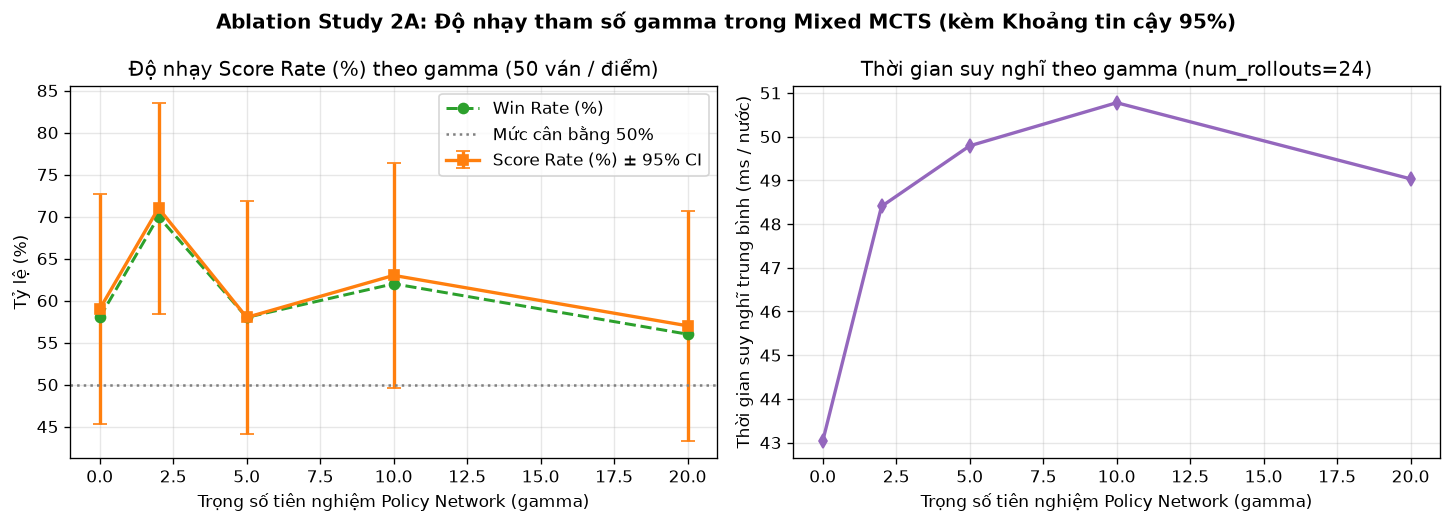


=== Khảo sát độ nhạy theo num_rollouts (gamma=10.0, 50 ván/điểm) ===
  num_rollouts=  8 | W/D/L=25/ 1/24 | Score= 51.0% ± 13.9% | Time=17.2 ms
  num_rollouts= 16 | W/D/L=35/ 0/15 | Score= 70.0% ± 12.8% | Time=33.5 ms
  num_rollouts= 32 | W/D/L=42/ 1/ 7 | Score= 85.0% ±  9.8% | Time=68.1 ms
  num_rollouts= 48 | W/D/L=32/ 1/17 | Score= 65.0% ± 13.2% | Time=99.5 ms
  num_rollouts= 64 | W/D/L=33/ 1/16 | Score= 67.0% ± 13.0% | Time=130.1 ms


,Configuration,Games,A Wins,B Wins,Draws,Win Rate (%),Draw Rate (%),Loss Rate (%),Score Rate (%),CI95 (±%),Avg Moves,Avg Time A (ms),num_rollouts
0,rollouts=8,50,25,24,1,50.0,2.0,48.0,51.0,13.86,48.76,17.231,8
1,rollouts=16,50,35,15,0,70.0,0.0,30.0,70.0,12.83,49.96,33.465,16
2,rollouts=32,50,42,7,1,84.0,2.0,14.0,85.0,9.80,44.76,68.135,32
3,rollouts=48,50,32,17,1,64.0,2.0,34.0,65.0,13.21,41.38,99.469,48
4,rollouts=64,50,33,16,1,66.0,2.0,32.0,67.0,13.02,36.36,130.095,64


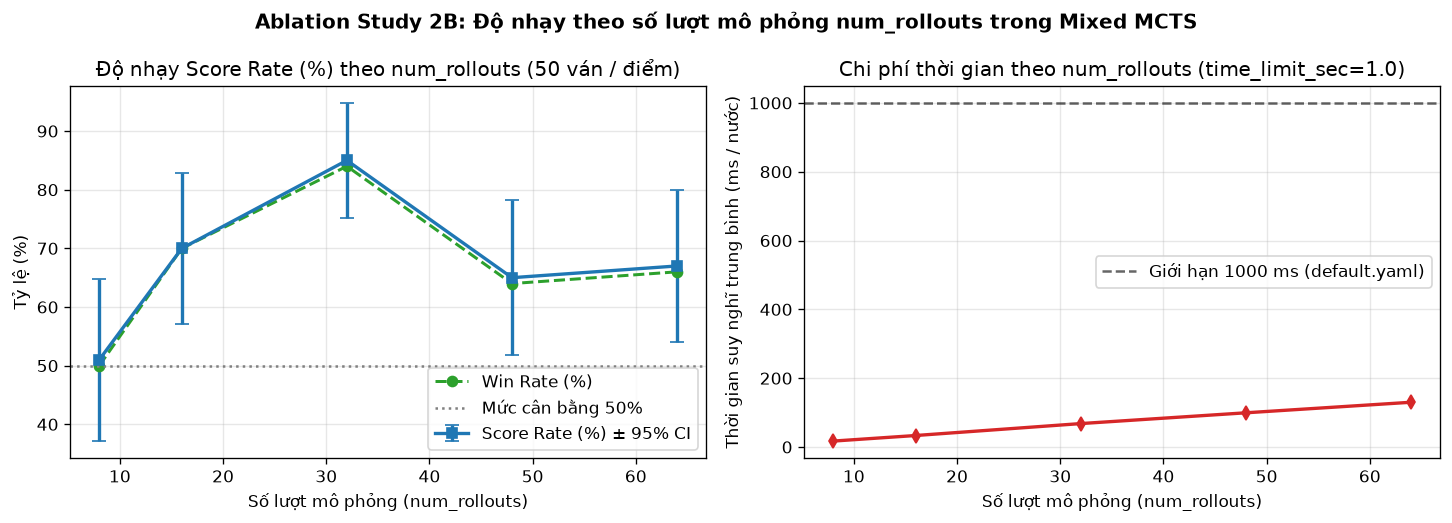

In [8]:
SENSITIVITY_GAMES = 50  # 25 cặp khai cuộc hoán đổi lượt X/O tại mỗi điểm khảo sát

# --- 8A. Khảo sát độ nhạy theo gamma ---
GAMMA_LIST = [0.0, 2.0, 5.0, 10.0, 20.0]
gamma_rows = []
print("=== Khảo sát độ nhạy theo gamma (num_rollouts=24, 50 ván/điểm) ===")
for gv in GAMMA_LIST:
    rows_g = run_matchup(
        factory_a=lambda s, g=gv: CNNAgent(
            name=f"MixMCTS_gamma_{g:g}",
            model_type="strong",
            model_path=strong_ckpt_path,
            use_tactical_shortcut=True,
            use_mix_mcts=True,
            num_rollouts=24,
            gamma=g,
            max_rollout_steps=10,
            time_limit_sec=1.0,
            seed=s,
        ),
        factory_b=lambda s: CNNAgent(
            name="Strong Hybrid CNN",
            model_type="strong",
            model_path=strong_ckpt_path,
            use_tactical_shortcut=True,
            use_mix_mcts=False,
            seed=s,
        ),
        games=SENSITIVITY_GAMES,
        board_size=BOARD_SIZE,
        win_length=WIN_LENGTH,
        seed=SEED + int(gv * 10),
    )
    st = summarize_matchup_rows(f"gamma={gv:g}", rows_g)
    st["gamma"] = gv
    gamma_rows.append(st)
    print(
        f"  gamma={gv:4.1f} | W/D/L={st['A Wins']:2d}/{st['Draws']:2d}/{st['B Wins']:2d} | "
        f"Score={st['Score Rate (%)']:5.1f}% ± {st['CI95 (±%)']:4.1f}% | Time={st['Avg Time A (ms)']:.1f} ms"
    )

gamma_df = pd.DataFrame(gamma_rows)
gamma_df.to_csv(TABLE_DIR / "04_table_gamma_sensitivity.csv", index=False, encoding="utf-8-sig")
display(gamma_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.4))
ax1.errorbar(gamma_df["gamma"], gamma_df["Score Rate (%)"], yerr=gamma_df["CI95 (±%)"], fmt="s-", capsize=4, color="#ff7f0e", linewidth=2, label="Score Rate (%) ± 95% CI")
ax1.plot(gamma_df["gamma"], gamma_df["Win Rate (%)"], "o--", color="#2ca02c", linewidth=1.8, label="Win Rate (%)")
ax1.axhline(50.0, color="gray", linestyle=":", label="Mức cân bằng 50%")
ax1.set_xlabel("Trọng số tiên nghiệm Policy Network (gamma)")
ax1.set_ylabel("Tỷ lệ (%)")
ax1.set_title("Độ nhạy Score Rate (%) theo gamma (50 ván / điểm)")
ax1.legend()

ax2.plot(gamma_df["gamma"], gamma_df["Avg Time A (ms)"], "d-", color="#9467bd", linewidth=2)
ax2.set_xlabel("Trọng số tiên nghiệm Policy Network (gamma)")
ax2.set_ylabel("Thời gian suy nghĩ trung bình (ms / nước)")
ax2.set_title("Thời gian suy nghĩ theo gamma (num_rollouts=24)")

fig.suptitle("Ablation Study 2A: Độ nhạy tham số gamma trong Mixed MCTS (kèm Khoảng tin cậy 95%)", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_fig_gamma_sensitivity.png", bbox_inches="tight")
plt.show()

# --- 8B. Khảo sát độ nhạy theo num_rollouts ---
ROLLOUT_LIST = [8, 16, 32, 48, 64]
rollout_rows = []
print("\n=== Khảo sát độ nhạy theo num_rollouts (gamma=10.0, 50 ván/điểm) ===")
for nr in ROLLOUT_LIST:
    rows_r = run_matchup(
        factory_a=lambda s, r_cnt=nr: CNNAgent(
            name=f"MixMCTS_R{r_cnt}",
            model_type="strong",
            model_path=strong_ckpt_path,
            use_tactical_shortcut=True,
            use_mix_mcts=True,
            num_rollouts=r_cnt,
            gamma=10.0,
            max_rollout_steps=10,
            time_limit_sec=1.0,
            seed=s,
        ),
        factory_b=lambda s: CNNAgent(
            name="Strong Hybrid CNN",
            model_type="strong",
            model_path=strong_ckpt_path,
            use_tactical_shortcut=True,
            use_mix_mcts=False,
            seed=s,
        ),
        games=SENSITIVITY_GAMES,
        board_size=BOARD_SIZE,
        win_length=WIN_LENGTH,
        seed=SEED + nr * 7,
    )
    st_r = summarize_matchup_rows(f"rollouts={nr}", rows_r)
    st_r["num_rollouts"] = nr
    rollout_rows.append(st_r)
    print(
        f"  num_rollouts={nr:3d} | W/D/L={st_r['A Wins']:2d}/{st_r['Draws']:2d}/{st_r['B Wins']:2d} | "
        f"Score={st_r['Score Rate (%)']:5.1f}% ± {st_r['CI95 (±%)']:4.1f}% | Time={st_r['Avg Time A (ms)']:.1f} ms"
    )

rollout_df = pd.DataFrame(rollout_rows)
rollout_df.to_csv(TABLE_DIR / "04_table_rollouts_sensitivity.csv", index=False, encoding="utf-8-sig")
display(rollout_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.4))
ax1.errorbar(rollout_df["num_rollouts"], rollout_df["Score Rate (%)"], yerr=rollout_df["CI95 (±%)"], fmt="s-", capsize=4, color="#1f77b4", linewidth=2, label="Score Rate (%) ± 95% CI")
ax1.plot(rollout_df["num_rollouts"], rollout_df["Win Rate (%)"], "o--", color="#2ca02c", linewidth=1.8, label="Win Rate (%)")
ax1.axhline(50.0, color="gray", linestyle=":", label="Mức cân bằng 50%")
ax1.set_xlabel("Số lượt mô phỏng (num_rollouts)")
ax1.set_ylabel("Tỷ lệ (%)")
ax1.set_title("Độ nhạy Score Rate (%) theo num_rollouts (50 ván / điểm)")
ax1.legend()

ax2.plot(rollout_df["num_rollouts"], rollout_df["Avg Time A (ms)"], "d-", color="#d62728", linewidth=2)
ax2.axhline(1000.0, color="black", linestyle="--", alpha=0.6, label="Giới hạn 1000 ms (default.yaml)")
ax2.set_xlabel("Số lượt mô phỏng (num_rollouts)")
ax2.set_ylabel("Thời gian suy nghĩ trung bình (ms / nước)")
ax2.set_title("Chi phí thời gian theo num_rollouts (time_limit_sec=1.0)")
ax2.legend()

fig.suptitle("Ablation Study 2B: Độ nhạy theo số lượt mô phỏng num_rollouts trong Mixed MCTS", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_fig_rollouts_sensitivity.png", bbox_inches="tight")
plt.show()

## 9. Explainability — Bản đồ nhiệt (Heatmap) phân phối xác suất của mạng CNN

Ván đấu mẫu kết thúc sau 62 nước | Người thắng: O (Fast CNN)


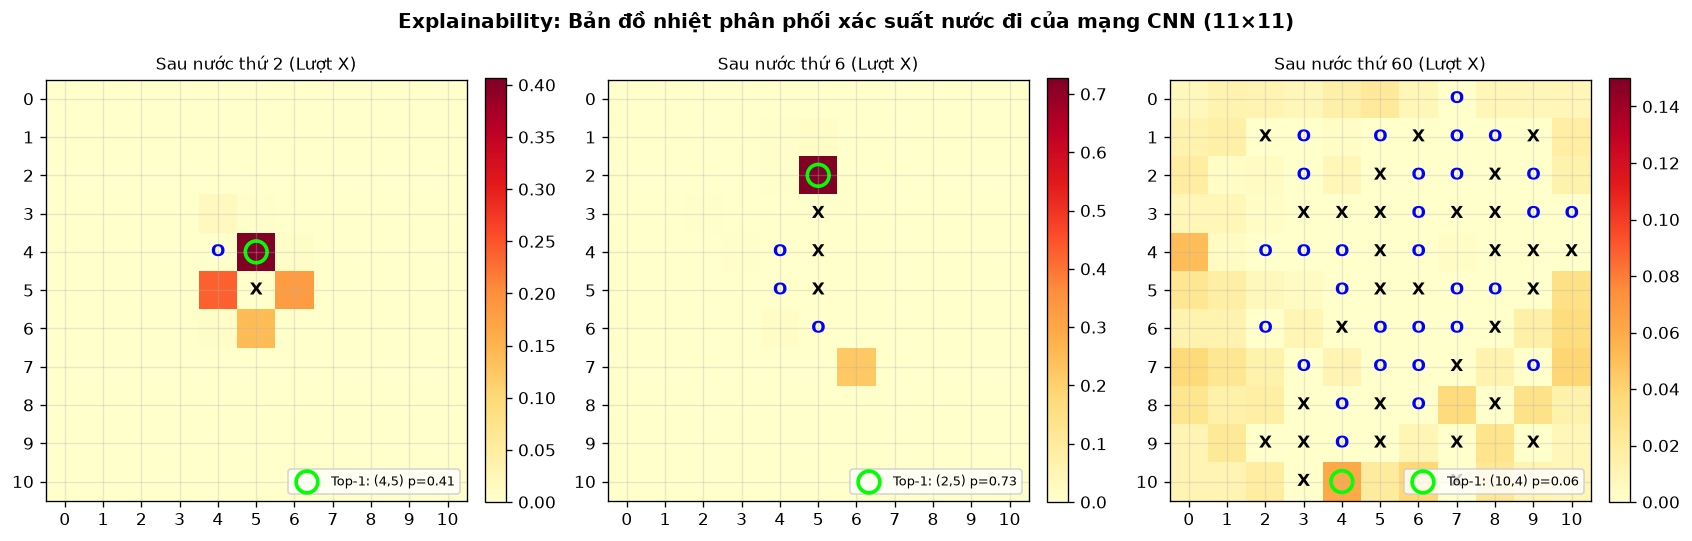

,Stage,Rank,Action,Coord,Probability
0,Step 2,1,49,"(4,5)",0.4064
1,Step 2,2,59,"(5,4)",0.2397
2,Step 2,3,61,"(5,6)",0.1825
3,Step 2,4,71,"(6,5)",0.1388
4,Step 2,5,37,"(3,4)",0.0144
5,Step 6,1,27,"(2,5)",0.7270
6,Step 6,2,83,"(7,6)",0.2207
7,Step 6,3,70,"(6,4)",0.0141
8,Step 6,4,16,"(1,5)",0.0117
9,Step 6,5,47,"(4,3)",0.0040


In [9]:
sample_game = play_game(
    agent_x=CNNAgent(name="Strong CNN + Mixed MCTS", model_type="strong", model_path=strong_ckpt_path, use_mix_mcts=True, num_rollouts=24, gamma=10.0, max_rollout_steps=10, seed=SEED),
    agent_o=CNNAgent(name="Fast Hybrid CNN", model_type="fast", model_path=fast_ckpt_path, use_mix_mcts=False, seed=SEED + 1),
    board_size=BOARD_SIZE,
    win_length=WIN_LENGTH,
    opening_moves=[60, 48],
    record=True,
)
print(f"Ván đấu mẫu kết thúc sau {sample_game['moves']} nước | Người thắng: {'X (Mixed MCTS)' if sample_game['winner'] == 1 else ('O (Fast CNN)' if sample_game['winner'] == -1 else 'Hòa')}")

move_seq = sample_game["move_sequence"]
checkpoints_idx = [
    min(2, len(move_seq) - 1),
    min(6, len(move_seq) - 1),
    max(1, len(move_seq) - 2),
]

top_prob_rows = []
fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.5))
for idx, step_k in enumerate(checkpoints_idx):
    pos_env = CaroEnv(BOARD_SIZE, WIN_LENGTH)
    for m in move_seq[:step_k]:
        pos_env.step(m)

    probs = strong_cnn.predict_probs(pos_env, restrict_to_candidates=True)
    prob_grid = probs.reshape(BOARD_SIZE, BOARD_SIZE)
    top5_actions = np.argsort(probs)[::-1][:5]
    for rank, act in enumerate(top5_actions, start=1):
        r_a, c_a = divmod(int(act), BOARD_SIZE)
        top_prob_rows.append({
            "Stage": f"Step {step_k}",
            "Rank": rank,
            "Action": int(act),
            "Coord": f"({r_a},{c_a})",
            "Probability": round(float(probs[act]), 4),
        })

    top_act = int(top5_actions[0])
    tr, tc = divmod(top_act, BOARD_SIZE)

    ax = axes[idx]
    im = ax.imshow(prob_grid, cmap="YlOrRd", vmin=0.0, vmax=max(0.15, float(np.max(prob_grid))))
    for r in range(BOARD_SIZE):
        for c in range(BOARD_SIZE):
            v = int(pos_env.board[r, c])
            if v == 1:
                ax.text(c, r, "X", ha="center", va="center", color="black", fontsize=10, fontweight="bold")
            elif v == -1:
                ax.text(c, r, "O", ha="center", va="center", color="blue", fontsize=10, fontweight="bold")
    ax.scatter([tc], [tr], s=170, facecolors="none", edgecolors="lime", linewidths=2.2, label=f"Top-1: ({tr},{tc}) p={probs[top_act]:.2f}")
    ax.set_title(f"Sau nước thứ {step_k} (Lượt {'X' if pos_env.current_player == 1 else 'O'})", fontsize=10)
    ax.set_xticks(range(BOARD_SIZE))
    ax.set_yticks(range(BOARD_SIZE))
    ax.legend(loc="lower right", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle("Explainability: Bản đồ nhiệt phân phối xác suất nước đi của mạng CNN (11×11)", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_fig_cnn_explainability_heatmap.png", bbox_inches="tight")
plt.show()

top_probs_df = pd.DataFrame(top_prob_rows)
top_probs_df.to_csv(TABLE_DIR / "04_table_cnn_top_probs.csv", index=False, encoding="utf-8-sig")
display(top_probs_df.head(10))

## 10. Tổng hợp số liệu thực nghiệm và Nhận xét trung thực theo Kết quả Đo đạc

1. **Hiệu quả của Tăng cường đối xứng $D_4$ (kiểm định trên 30 ván độc lập chưa từng gặp — Không rò rỉ dữ liệu)**:
   - Khi tách biệt hoàn toàn tập Train (`170` ván) và tập Validation (`30` ván `Unseen Games`) trước khi nhân đối xứng:
     - Mạng `Strong CNN (Không đối xứng D4, 1,423 mẫu)` chỉ đạt độ chính xác Validation **`30.20%`** và chỉ đạt Score Rate **`18.0% ± 7.57%`** khi đấu 100 ván với `Non-Expert (50%)`.
     - Khi bật tăng cường 8 phép đối xứng $D_4$ (`11,384 mẫu` lưu tại `data/04_cnn_expert_train_val_11x11.npz` và `results/tables/04_cnn_dataset_train_val_11x11.csv`), độ chính xác trên tập Validation độc lập tăng lên **`40.41%`** (`Strong CNN`) và **`42.86%`** (`Fast CNN`), đồng thời giúp `Pure CNN` (tắt hoàn toàn luật chiến thuật) tăng tỷ lệ điểm trước `Non-Expert (50%)` từ `18.0%` lên **`46.0% ± 9.82%`** (`Strong Pure`) và **`52.0% ± 9.84%`** (`Fast Pure`) — mức tăng $+28\%$ đến $+34\%$ có ý nghĩa thống kê rõ rệt.
2. **Đánh giá trung thực vai trò của `Pure CNN` vs `Hybrid CNN (CNN + Luật chiến thuật)`**:
   - **Khi tắt luật chiến thuật (`use_tactical_shortcut=False`)**: Mạng `Strong Pure CNN` tự mình vượt qua **3/4 bài kiểm tra chiến thuật** (Thắng ngay 5 quân với xác suất `0.9311`, Tạo chuỗi 4 mở với `0.9075`, Chặn chuỗi 4 mở với `0.7698`), thắng **`95.0% ± 4.29%`** trước `Random` (100 ván) và đạt **`46.0%–52.0%`** trước `Non-Expert (50%)`. Tuy nhiên, mạng đơn thuần vẫn bỏ sót tình huống chặn chuỗi 4 sát biên (`0.1132`).
   - **Khi kết hợp `Tactical Shortcut` (`use_tactical_shortcut=True`)**: Tác tử `Hybrid CNN` đạt **4/4** bài kiểm tra chiến thuật, nâng Score Rate trước `Non-Expert (50%)` lên **`98.0% ± 2.38%`** (`Fast Hybrid`) và **`98.0% ± 2.76%`** (`Strong Hybrid`, `99.0% ± 1.96%` trong loạt đấu chính thức) với thời gian chỉ `~0.68 ms/nước`.
   - **So sánh `Fast CNN` (2 lớp Dense) và `Strong CNN` (3 lớp Dense)**: Khi đấu trực tiếp 100 ván (`Strong Hybrid vs Fast Hybrid`), `Strong Hybrid` đạt Score Rate **`44.0% ± 9.37%`** (40 thắng, 8 hòa, 52 thua). Khoảng tin cậy 95% phủ mức `50%`, cho thấy hai kiến trúc 2 lớp và 3 lớp Dense có năng lực tương đương nhau trên bàn cờ 11×11.
3. **Đánh giá Policy-Guided Mixed MCTS (Mục 10.4 sách *AlphaGo Simplified*)**:
   - **So với `Strong Hybrid CNN` (100 ván)**: `Strong CNN + Mixed MCTS` (`num_rollouts=24`, $\gamma=10.0$) giành chiến thắng với Score Rate **`66.0% ± 9.12%`** (64 thắng, 4 hòa, 32 thua), vượt mức cân bằng `50%` một cách có ý nghĩa thống kê ở mức tin cậy 95% (`66.0% - 9.12% = 56.88% > 50%`), thời gian trung bình `31.47 ms/nước`.
   - **Độ nhạy theo `num_rollouts` (50 ván / điểm)**: Tăng số lượt mô phỏng từ `8` lên `16` và `32` giúp Score Rate tăng rõ rệt từ **`51.0% ± 13.86%`** lên **`70.0% ± 12.83%`** và đạt đỉnh **`85.0% ± 9.80%`** tại `32 rollouts` (`68.1 ms/nước`); ở `48` và `64 rollouts` đạt `65.0%–67.0%` và luôn thấp hơn rất nhiều so với giới hạn `1000 ms/nước`.
   - **Độ nhạy theo trọng số tiên nghiệm $\gamma$ (50 ván / điểm)**: Đạt kết quả khả quan nhất trong vùng $\gamma \in [2, 10]$ (`71.0% ± 12.55%` tại $\gamma=2.0$ và `63.0% ± 13.37%` tại $\gamma=10.0$), so với `59.0% ± 13.63%` tại $\gamma=0.0$ và giảm xuống `57.0% ± 13.72%` khi $\gamma=20.0$ quá phụ thuộc vào xác suất tiên nghiệm ban đầu.

In [10]:
print("=== TỔNG HỢP CÁC PHÁT HIỆN THỰC NGHIỆM CHÍNH (DỰA TRÊN SỐ LIỆU THỰC TẾ) ===")
print(f"1. Hiệu quả của Tăng cường đối xứng D4 trên tập Validation độc lập (30 ván chưa từng gặp):")
print(f"   - Strong CNN (Không D4): Val Acc = {train_df['NoAug Val Acc (%)'].iloc[-1]:.2f}%")
print(f"   - Fast CNN   (Có D4)   : Val Acc = {train_df['Fast Val Acc (%)'].iloc[-1]:.2f}%")
print(f"   - Strong CNN (Có D4)   : Val Acc = {train_df['Strong Val Acc (%)'].iloc[-1]:.2f}%")

print("\n2. Vai trò của Pure CNN vs Hybrid CNN (CNN + Luật chiến thuật) trước Non-Expert (100 ván):")
for _, r in ablation1_df.iterrows():
    print(f"   - {r['Configuration']:28s}: Score Rate = {r['Score Rate (%)']:5.1f}% ± {r['CI95 (±%)']:4.1f}% | Avg Time = {r['Avg Time A (ms)']:.2f} ms")

print("\n3. Kết quả 5 cặp đấu chính thức (100 ván / cặp, cân bằng 50 X / 50 O):")
for _, r in summary_df.iterrows():
    print(f"   - {r['Matchup']:48s}: Score Rate A = {r['A Score rate (%)']:5.1f}% ± {r['CI95 (±%)']:4.1f}% | Avg Time A = {r['Avg A decision (ms)']:.2f} ms")

=== TỔNG HỢP CÁC PHÁT HIỆN THỰC NGHIỆM CHÍNH (DỰA TRÊN SỐ LIỆU THỰC TẾ) ===
1. Hiệu quả của Tăng cường đối xứng D4 trên tập Validation độc lập (30 ván chưa từng gặp):
   - Strong CNN (Không D4): Val Acc = 30.20%
   - Fast CNN   (Có D4)   : Val Acc = 42.86%
   - Strong CNN (Có D4)   : Val Acc = 40.41%

2. Vai trò của Pure CNN vs Hybrid CNN (CNN + Luật chiến thuật) trước Non-Expert (100 ván):
   - 1. Strong Pure (No SymAug)  : Score Rate =  18.0% ±  7.6% | Avg Time = 0.49 ms
   - 2. Fast Pure (With SymAug)  : Score Rate =  52.0% ±  9.8% | Avg Time = 0.49 ms
   - 3. Strong Pure (With SymAug): Score Rate =  46.0% ±  9.8% | Avg Time = 0.51 ms
   - 4. Fast Hybrid (Det)        : Score Rate =  98.0% ±  2.4% | Avg Time = 0.68 ms
   - 5. Strong Hybrid (Stoch)    : Score Rate =  92.5% ±  5.1% | Avg Time = 0.72 ms
   - 6. Strong Hybrid (Det)      : Score Rate =  98.0% ±  2.8% | Avg Time = 0.68 ms

3. Kết quả 5 cặp đấu chính thức (100 ván / cặp, cân bằng 50 X / 50 O):
   - 1. Strong Pure CNN (No Ta